In [1]:
import pandas as pd
import sklearn
import matplotlib.pyplot as plt

In [2]:
from google.colab import files

uploaded = files.upload()

Saving yield_df.csv to yield_df.csv


In [3]:
df = pd.read_csv("yield_df.csv")

print("Rows and columns:", df.shape)
print("Column names:", df.columns.tolist())

df.head()

Rows and columns: (28242, 8)
Column names: ['Unnamed: 0', 'Area', 'Item', 'Year', 'hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']


,Unnamed: 0,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


In [4]:
# Remove the old row-number column.
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

# Keep only records for India.
india_df = df[
    df["Area"].str.strip().str.lower() == "india"
].copy()

print("India rows:", len(india_df))
print("Crops:", india_df["Item"].unique().tolist())
print("Missing values:")
print(india_df.isna().sum())

india_df.head()

India rows: 4048
Crops: ['Cassava', 'Maize', 'Potatoes', 'Rice, paddy', 'Sorghum', 'Soybeans', 'Sweet potatoes', 'Wheat']
Missing values:
Area                             0
Item                             0
Year                             0
hg/ha_yield                      0
average_rain_fall_mm_per_year    0
pesticides_tonnes                0
avg_temp                         0
dtype: int64


,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
10502,India,Cassava,1990,205381,1083.0,75000.0,25.58
10503,India,Cassava,1990,205381,1083.0,75000.0,26.88
10504,India,Cassava,1990,205381,1083.0,75000.0,25.79
10505,India,Cassava,1990,205381,1083.0,75000.0,24.10
10506,India,Cassava,1990,205381,1083.0,75000.0,25.25


In [5]:
# Select the six crops discussed in the original paper.
selected_crops = [
    "Potatoes",
    "Rice, paddy",
    "Sorghum",
    "Soybeans",
    "Sweet potatoes",
    "Wheat"
]

crop_df = india_df[
    india_df["Item"].isin(selected_crops)
].copy()

# Remove only completely identical rows.
before = len(crop_df)
crop_df = crop_df.drop_duplicates().reset_index(drop=True)

print("Rows before removing duplicates:", before)
print("Exact duplicate rows removed:", before - len(crop_df))
print("Rows remaining:", len(crop_df))
print("Year range:",
      crop_df["Year"].min(), "to", crop_df["Year"].max())

print("\nNumber of rows for each crop and year:")
print(
    crop_df.groupby(["Item", "Year"])
    .size()
    .head(12)
)

Rows before removing duplicates: 3036
Exact duplicate rows removed: 498
Rows remaining: 2538
Year range: 1990 to 2013

Number of rows for each crop and year:
Item      Year
Potatoes  1990    18
          1991    18
          1992    19
          1993    19
          1994    17
          1995    19
          1996    18
          1997    17
          1998    17
          1999    19
          2000    18
          2001    18
dtype: int64


In [6]:
# Keep the latest five available years for testing.
years = sorted(crop_df["Year"].unique())
test_years = years[-5:]

train_df = crop_df[
    ~crop_df["Year"].isin(test_years)
].copy()

test_df = crop_df[
    crop_df["Year"].isin(test_years)
].copy()

print("Training years:",
      sorted(train_df["Year"].unique().tolist()))
print("Testing years:", test_years)

print("\nTraining rows:", len(train_df))
print("Testing rows:", len(test_df))

# Confirm that no year appears in both sets.
overlap = set(train_df["Year"]) & set(test_df["Year"])
print("Years shared between sets:", overlap)

Training years: [1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2004, 2005, 2006, 2007, 2008]
Testing years: [np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013)]

Training rows: 1980
Testing rows: 558
Years shared between sets: set()


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Information the model uses to predict yield.
features = [
    "Item",
    "average_rain_fall_mm_per_year",
    "pesticides_tonnes",
    "avg_temp"
]

X_train = train_df[features]
y_train = train_df["hg/ha_yield"]

X_test = test_df[features]
y_test = test_df["hg/ha_yield"]

# Convert crop names into numerical columns.
preprocessor = ColumnTransformer(
    transformers=[
        ("crop", OneHotEncoder(handle_unknown="ignore"), ["Item"])
    ],
    remainder="passthrough"
)

# Join data preparation and the prediction model.
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

print("First model trained successfully!")

First model trained successfully!


In [8]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict yields for the later years kept aside for testing.
predictions = linear_model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = mean_squared_error(y_test, predictions) ** 0.5
r2 = r2_score(y_test, predictions)

print("LINEAR REGRESSION — TEST RESULTS")
print("MAE:", round(mae, 2), "hg/ha")
print("RMSE:", round(rmse, 2), "hg/ha")
print("R² score:", round(r2, 4))

# Display a few actual and predicted values.
results = test_df[["Item", "Year", "hg/ha_yield"]].copy()
results = results.rename(columns={"hg/ha_yield": "Actual yield"})
results["Predicted yield"] = predictions.round(2)

results.head(10)

LINEAR REGRESSION — TEST RESULTS
MAE: 9877.71 hg/ha
RMSE: 17723.66 hg/ha
R² score: 0.9391


,Item,Year,Actual yield,Predicted yield
1980,Potatoes,2009,188103,177258.64
1981,Potatoes,2009,188103,177087.03
1982,Potatoes,2009,188103,177235.39
1983,Potatoes,2009,188103,177444.65
1984,Potatoes,2009,188103,177349.43
1985,Potatoes,2009,188103,177244.25
1986,Potatoes,2009,188103,177192.21
1987,Potatoes,2009,188103,177094.78
1988,Potatoes,2009,188103,177274.14
1989,Potatoes,2009,188103,177217.67


In [9]:
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor

# Use a separate copy of the data-preparation step.
gradient_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", GradientBoostingRegressor(random_state=42))
])

gradient_model.fit(X_train, y_train)

gradient_predictions = gradient_model.predict(X_test)

comparison = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MAE (hg/ha)": mae,
        "RMSE (hg/ha)": rmse,
        "R²": r2
    },
    {
        "Model": "Gradient Boosting",
        "MAE (hg/ha)": mean_absolute_error(
            y_test, gradient_predictions
        ),
        "RMSE (hg/ha)": mean_squared_error(
            y_test, gradient_predictions
        ) ** 0.5,
        "R²": r2_score(y_test, gradient_predictions)
    }
])

print("MODEL COMPARISON — SAME HELD-OUT YEARS")
print(comparison.round(4).to_string(index=False))


MODEL COMPARISON — SAME HELD-OUT YEARS
            Model  MAE (hg/ha)  RMSE (hg/ha)     R²
Linear Regression    9877.7113    17723.6588 0.9391
Gradient Boosting    9232.7589    16668.7396 0.9461


In [10]:
# Collect the Gradient Boosting predictions.
crop_results = test_df[
    ["Item", "Year", "hg/ha_yield"]
].copy()

crop_results["Predicted yield"] = gradient_predictions

# Calculate errors separately for each crop.
summary = []

for crop, group in crop_results.groupby("Item"):
    actual = group["hg/ha_yield"]
    predicted = group["Predicted yield"]

    summary.append({
        "Crop": crop,
        "Test rows": len(group),
        "MAE (tonnes/ha)": (
            mean_absolute_error(actual, predicted) / 10000
        ),
        "R²": r2_score(actual, predicted)
    })

crop_scores = pd.DataFrame(summary)

print("GRADIENT BOOSTING — RESULTS FOR EACH CROP")
print(crop_scores.round(3).to_string(index=False))

GRADIENT BOOSTING — RESULTS FOR EACH CROP
          Crop  Test rows  MAE (tonnes/ha)      R²
      Potatoes         93            3.421  -5.272
   Rice, paddy         93            0.549 -12.005
       Sorghum         93            0.079  -1.765
      Soybeans         93            0.210  -1.878
Sweet potatoes         93            0.871  -4.811
         Wheat         93            0.410  -9.670


In [11]:
# Learn each crop's average yield from training data only.
training_crop_means = train_df.groupby("Item")["hg/ha_yield"].mean()

# Predict the training average for each test crop.
baseline_predictions = test_df["Item"].map(training_crop_means)

baseline_row = pd.DataFrame([{
    "Model": "Training crop-average baseline",
    "MAE (hg/ha)": mean_absolute_error(
        y_test, baseline_predictions
    ),
    "RMSE (hg/ha)": mean_squared_error(
        y_test, baseline_predictions
    ) ** 0.5,
    "R²": r2_score(y_test, baseline_predictions)
}])

comparison_with_baseline = pd.concat(
    [comparison, baseline_row],
    ignore_index=True
)

print(comparison_with_baseline.round(4).to_string(index=False))

                         Model  MAE (hg/ha)  RMSE (hg/ha)     R²
             Linear Regression    9877.7113    17723.6588 0.9391
             Gradient Boosting    9232.7589    16668.7396 0.9461
Training crop-average baseline   10133.2214    17770.3165 0.9388


In [12]:
# Check whether repeated crop-year records share the same yield.
record_check = crop_df.groupby(["Item", "Year"]).agg(
    rows=("hg/ha_yield", "size"),
    distinct_yields=("hg/ha_yield", "nunique"),
    distinct_temperatures=("avg_temp", "nunique")
).reset_index()

print("Total rows:", len(crop_df))
print("Distinct crop-year groups:", len(record_check))

print("\nGroups with more than one yield value:")
print((record_check["distinct_yields"] > 1).sum())

print("\nExample groups:")
print(record_check.head(12).to_string(index=False))

Total rows: 2538
Distinct crop-year groups: 138

Groups with more than one yield value:
0

Example groups:
    Item  Year  rows  distinct_yields  distinct_temperatures
Potatoes  1990    18                1                     18
Potatoes  1991    18                1                     18
Potatoes  1992    19                1                     19
Potatoes  1993    19                1                     19
Potatoes  1994    17                1                     17
Potatoes  1995    19                1                     19
Potatoes  1996    18                1                     18
Potatoes  1997    17                1                     17
Potatoes  1998    17                1                     17
Potatoes  1999    19                1                     19
Potatoes  2000    18                1                     18
Potatoes  2001    18                1                     18


In [13]:
# Check how many different input values each crop-year contains.
input_check = crop_df.groupby(["Item", "Year"]).agg(
    rainfall_values=("average_rain_fall_mm_per_year", "nunique"),
    pesticide_values=("pesticides_tonnes", "nunique"),
    temperature_values=("avg_temp", "nunique")
)

print("Largest number of distinct values within a crop-year:")
print(input_check.max())

print("\nYears available:")
print(sorted(crop_df["Year"].unique().tolist()))

Largest number of distinct values within a crop-year:
rainfall_values        1
pesticide_values       1
temperature_values    19
dtype: int64

Years available:
[1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013]


In [14]:
# Create one annual record for each crop.
# Assumption: average the temperature values in the cleaned table.
annual_df = crop_df.groupby(
    ["Item", "Year"], as_index=False
).agg(
    yield_hg_ha=("hg/ha_yield", "first"),
    rainfall_mm=("average_rain_fall_mm_per_year", "first"),
    pesticides_tonnes=("pesticides_tonnes", "first"),
    mean_source_temperature_c=("avg_temp", "mean")
)

print("Annual dataset rows:", len(annual_df))
print("Records per crop:")
print(annual_df.groupby("Item").size())

annual_df.head()

Annual dataset rows: 138
Records per crop:
Item
Potatoes          23
Rice, paddy       23
Sorghum           23
Soybeans          23
Sweet potatoes    23
Wheat             23
dtype: int64


,Item,Year,yield_hg_ha,rainfall_mm,pesticides_tonnes,mean_source_temperature_c
0,Potatoes,1990,157136,1083.0,75000.0,25.643889
1,Potatoes,1991,162540,1083.0,72133.0,25.811111
2,Potatoes,1992,160294,1083.0,70791.0,25.775789
3,Potatoes,1993,149024,1083.0,66388.0,25.944737
4,Potatoes,1994,166101,1083.0,61357.0,25.764118


In [15]:
# Split the annual records by year.
annual_train = annual_df[annual_df["Year"] < 2009].copy()
annual_test = annual_df[annual_df["Year"] >= 2009].copy()

annual_features = [
    "Item",
    "rainfall_mm",
    "pesticides_tonnes",
    "mean_source_temperature_c"
]

X_annual_train = annual_train[annual_features]
y_annual_train = annual_train["yield_hg_ha"]

X_annual_test = annual_test[annual_features]
y_annual_test = annual_test["yield_hg_ha"]

annual_preprocessor = ColumnTransformer(
    transformers=[
        ("crop", OneHotEncoder(handle_unknown="ignore"), ["Item"])
    ],
    remainder="passthrough"
)

annual_models = {
    "Linear Regression": Pipeline([
        ("prepare", clone(annual_preprocessor)),
        ("model", LinearRegression())
    ]),
    "Gradient Boosting": Pipeline([
        ("prepare", clone(annual_preprocessor)),
        ("model", GradientBoostingRegressor(random_state=42))
    ])
}

# Baseline: each crop's mean yield from training years only.
annual_crop_means = annual_train.groupby("Item")["yield_hg_ha"].mean()

annual_predictions = {
    "Crop-average baseline":
        annual_test["Item"].map(annual_crop_means).to_numpy()
}

for name, model in annual_models.items():
    model.fit(X_annual_train, y_annual_train)
    annual_predictions[name] = model.predict(X_annual_test)

scores = []

for name, predicted in annual_predictions.items():
    scores.append({
        "Model": name,
        "MAE (tonnes/ha)": mean_absolute_error(
            y_annual_test, predicted
        ) / 10000,
        "RMSE (tonnes/ha)": (
            mean_squared_error(y_annual_test, predicted) ** 0.5
        ) / 10000,
        "R²": r2_score(y_annual_test, predicted)
    })

annual_comparison = pd.DataFrame(scores)

print("Training records:", len(annual_train))
print("Testing records:", len(annual_test))
print("\nANNUAL DATA — EXPLORATORY TEST RESULTS")
print(annual_comparison.round(4).to_string(index=False))

Training records: 108
Testing records: 30

ANNUAL DATA — EXPLORATORY TEST RESULTS
                Model  MAE (tonnes/ha)  RMSE (tonnes/ha)     R²
Crop-average baseline           1.0037            1.7639 0.9394
    Linear Regression           1.0223            1.7917 0.9375
    Gradient Boosting           1.0214            1.8676 0.9321


In [16]:
# Find each crop's most recent yield in the training years only.
last_known_yields = (
    annual_train.sort_values("Year")
    .groupby("Item")["yield_hg_ha"]
    .last()
)

last_yield_predictions = (
    annual_test["Item"].map(last_known_yields).to_numpy()
)

annual_predictions["Last-known-yield baseline"] = last_yield_predictions

last_yield_score = pd.DataFrame([{
    "Model": "Last-known-yield baseline",
    "MAE (tonnes/ha)": mean_absolute_error(
        y_annual_test, last_yield_predictions
    ) / 10000,
    "RMSE (tonnes/ha)": (
        mean_squared_error(y_annual_test, last_yield_predictions) ** 0.5
    ) / 10000,
    "R²": r2_score(y_annual_test, last_yield_predictions)
}])

annual_comparison = pd.concat([
    annual_comparison[
        annual_comparison["Model"] != "Last-known-yield baseline"
    ],
    last_yield_score
], ignore_index=True)

print(annual_comparison.round(4).to_string(index=False))

                    Model  MAE (tonnes/ha)  RMSE (tonnes/ha)     R²
    Crop-average baseline           1.0037            1.7639 0.9394
        Linear Regression           1.0223            1.7917 0.9375
        Gradient Boosting           1.0214            1.8676 0.9321
Last-known-yield baseline           0.5649            1.0626 0.9780


In [17]:
# Validation uses only our earlier training data.
development_df = annual_train.copy()

validation_periods = [
    (1998, [1999, 2000, 2001]),
    (2001, [2002, 2004, 2005]),
    (2005, [2006, 2007, 2008])
]

for round_number, (cutoff, validation_years) in enumerate(
    validation_periods, start=1
):
    fold_train = development_df[
        development_df["Year"] <= cutoff
    ]

    fold_validation = development_df[
        development_df["Year"].isin(validation_years)
    ]

    # Check that every training year is before validation.
    assert not fold_train.empty
    assert not fold_validation.empty
    assert fold_train["Year"].max() < fold_validation["Year"].min()
    assert fold_validation["Year"].max() < 2009

    print(f"\nRound {round_number}")
    print("Train through:", cutoff)
    print("Validation years:", validation_years)
    print("Training rows:", len(fold_train))
    print("Validation rows:", len(fold_validation))

print("\nValidation periods are ready.")


Round 1
Train through: 1998
Validation years: [1999, 2000, 2001]
Training rows: 54
Validation rows: 18

Round 2
Train through: 2001
Validation years: [2002, 2004, 2005]
Training rows: 72
Validation rows: 18

Round 3
Train through: 2005
Validation years: [2006, 2007, 2008]
Training rows: 90
Validation rows: 18

Validation periods are ready.


In [18]:
validation_scores = []

for round_number, (cutoff, validation_years) in enumerate(
    validation_periods, start=1
):
    fold_train = development_df[
        development_df["Year"] <= cutoff
    ].copy()

    fold_validation = development_df[
        development_df["Year"].isin(validation_years)
    ].copy()

    X_fold_train = fold_train[annual_features]
    y_fold_train = fold_train["yield_hg_ha"]

    X_fold_validation = fold_validation[annual_features]
    y_fold_validation = fold_validation["yield_hg_ha"]

    # Calculate baselines from this round's training data only.
    crop_means = fold_train.groupby("Item")["yield_hg_ha"].mean()

    last_yields = (
        fold_train.sort_values("Year")
        .groupby("Item")["yield_hg_ha"]
        .last()
    )

    fold_predictions = {
        "Crop-average baseline":
            fold_validation["Item"].map(crop_means).to_numpy(),
        "Last-known-yield baseline":
            fold_validation["Item"].map(last_yields).to_numpy()
    }

    # Clone creates a fresh, untrained model for each round.
    for name, model_template in annual_models.items():
        model = clone(model_template)
        model.fit(X_fold_train, y_fold_train)

        fold_predictions[name] = model.predict(
            X_fold_validation
        )

    for name, predicted in fold_predictions.items():
        validation_scores.append({
            "Round": round_number,
            "Model": name,
            "MAE (tonnes/ha)": mean_absolute_error(
                y_fold_validation, predicted
            ) / 10000,
            "RMSE (tonnes/ha)": (
                mean_squared_error(y_fold_validation, predicted) ** 0.5
            ) / 10000
        })

validation_results = pd.DataFrame(validation_scores)

print("ERRORS FOR EACH VALIDATION ROUND")
print(
    validation_results.round(4).to_string(index=False)
)

validation_summary = (
    validation_results.groupby("Model")[
        ["MAE (tonnes/ha)", "RMSE (tonnes/ha)"]
    ]
    .mean()
    .sort_values("MAE (tonnes/ha)")
)

print("\nAVERAGE ERRORS ACROSS THREE ROUNDS")
print(validation_summary.round(4).to_string())

ERRORS FOR EACH VALIDATION ROUND
 Round                     Model  MAE (tonnes/ha)  RMSE (tonnes/ha)
     1     Crop-average baseline           0.5468            0.8848
     1 Last-known-yield baseline           0.7634            1.5051
     1         Linear Regression           0.4876            0.7914
     1         Gradient Boosting           0.7634            1.4793
     2     Crop-average baseline           0.5239            0.9484
     2 Last-known-yield baseline           0.2004            0.3335
     2         Linear Regression           0.5804            0.8820
     2         Gradient Boosting           0.4744            0.9506
     3     Crop-average baseline           0.4096            0.6542
     3 Last-known-yield baseline           0.2604            0.6068
     3         Linear Regression           0.6080            0.7195
     3         Gradient Boosting           0.2868            0.5985

AVERAGE ERRORS ACROSS THREE ROUNDS
                           MAE (tonnes/ha)  RMS

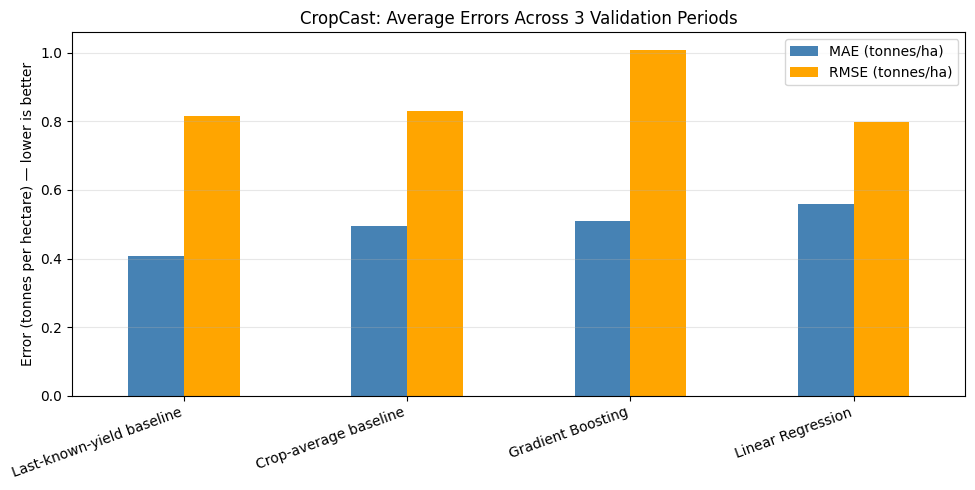

In [19]:
# Plot the average validation errors.
chart_data = validation_summary.sort_values(
    "MAE (tonnes/ha)"
)

chart_data.plot(
    kind="bar",
    y=["MAE (tonnes/ha)", "RMSE (tonnes/ha)"],
    figsize=(10, 5),
    color=["steelblue", "orange"]
)

plt.title("CropCast: Average Errors Across 3 Validation Periods")
plt.ylabel("Error (tonnes per hectare) — lower is better")
plt.xlabel("")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "cropcast_validation_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [20]:
def demonstrate_prediction(crop, rainfall, pesticides, temperature):
    # Check the crop name.
    if crop not in annual_train["Item"].unique():
        print("Crop not found. Use one of these:")
        print(sorted(annual_train["Item"].unique()))
        return

    # Prepare one input record in the same format as training.
    sample = pd.DataFrame([{
        "Item": crop,
        "rainfall_mm": rainfall,
        "pesticides_tonnes": pesticides,
        "mean_source_temperature_c": temperature
    }])

    print("CROPCAST — EDUCATIONAL DEMONSTRATION")
    print("Crop:", crop)
    print("Models trained on records before 2009.")

    # Warn when numerical inputs fall outside training ranges.
    for column in annual_features[1:]:
        lowest = annual_train[column].min()
        highest = annual_train[column].max()

        if not lowest <= sample[column].iloc[0] <= highest:
            print("Warning: outside training range:", column)

    print("\nYield estimates (tonnes per hectare):")

    # This historical baseline does not use weather inputs.
    historical = last_known_yields[crop] / 10000
    print(f"Last-known-yield baseline: {historical:.3f}")

    for name, model in annual_models.items():
        estimate = model.predict(sample)[0] / 10000
        print(f"{name}: {estimate:.3f}")

        if estimate < 0:
            print("Warning: negative yield is not physically valid.")

    print("\nThese are experimental estimates, not guaranteed forecasts.")
    print("Pesticide input is an aggregate historical value in tonnes,")
    print("not a recommended dose for an individual farm.")


# Use an existing training record for the first demonstration.
example = annual_train[
    annual_train["Item"] == "Rice, paddy"
].sort_values("Year").iloc[-1]

demonstrate_prediction(
    crop=example["Item"],
    rainfall=example["rainfall_mm"],
    pesticides=example["pesticides_tonnes"],
    temperature=example["mean_source_temperature_c"]
)


CROPCAST — EDUCATIONAL DEMONSTRATION
Crop: Rice, paddy
Models trained on records before 2009.

Yield estimates (tonnes per hectare):
Last-known-yield baseline: 3.251
Linear Regression: 3.567
Gradient Boosting: 3.213

These are experimental estimates, not guaranteed forecasts.
Pesticide input is an aggregate historical value in tonnes,
not a recommended dose for an individual farm.


In [21]:
import ipywidgets as widgets
from IPython.display import display, clear_output

crop_box = widgets.Dropdown(
    options=sorted(annual_train["Item"].unique()),
    value="Rice, paddy",
    description="Crop:"
)

rain_box = widgets.FloatText(description="Rainfall mm:")
pesticide_box = widgets.FloatText(description="Pesticides t:")
temperature_box = widgets.FloatText(description="Mean temp °C:")

predict_button = widgets.Button(
    description="Predict yield",
    button_style="success"
)

output_box = widgets.Output()


def fill_example(change=None):
    # Fill the boxes with the selected crop's latest training record.
    record = annual_train[
        annual_train["Item"] == crop_box.value
    ].sort_values("Year").iloc[-1]

    rain_box.value = float(record["rainfall_mm"])
    pesticide_box.value = float(record["pesticides_tonnes"])
    temperature_box.value = float(
        record["mean_source_temperature_c"]
    )


def predict_clicked(button):
    with output_box:
        clear_output(wait=True)

        values = [
            rain_box.value,
            pesticide_box.value,
            temperature_box.value
        ]

        if not all(
            float("-inf") < value < float("inf")
            for value in values
        ):
            print("Please enter finite numbers in every box.")
            return

        if rain_box.value < 0 or pesticide_box.value < 0:
            print("Rainfall and pesticide use cannot be negative.")
            return

        demonstrate_prediction(
            crop_box.value,
            rain_box.value,
            pesticide_box.value,
            temperature_box.value
        )


crop_box.observe(fill_example, names="value")
predict_button.on_click(predict_clicked)

fill_example()

display(
    widgets.HTML(
        "<h3>CropCast — Educational Yield Demonstration</h3>"
        "<p>Boxes start with a historical training example. "
        "Changing the crop resets the example values.</p>"
        "<p>Pesticides: aggregate tonnes, not a farm dose. "
        "Temperature: mean of source values, not a verified "
        "national average.</p>"
    ),
    crop_box,
    rain_box,
    pesticide_box,
    temperature_box,
    predict_button,
    output_box
)

HTML(value='<h3>CropCast — Educational Yield Demonstration</h3><p>Boxes start with a historical training examp…

Dropdown(description='Crop:', index=1, options=('Potatoes', 'Rice, paddy', 'Sorghum', 'Soybeans', 'Sweet potat…

FloatText(value=1083.0, description='Rainfall mm:')

FloatText(value=14485.33, description='Pesticides t:')

FloatText(value=25.793684210526315, description='Mean temp °C:')

Button(button_style='success', description='Predict yield', style=ButtonStyle())

Output()

In [22]:
# Save the annual data and measured results.
annual_df.to_csv("cropcast_annual_data.csv", index=False)

annual_comparison.to_csv(
    "cropcast_exploratory_test_results.csv", index=False
)

validation_results.to_csv(
    "cropcast_validation_rounds.csv", index=False
)

validation_summary.to_csv(
    "cropcast_validation_summary.csv"
)

# Package these files and the chart together.
import zipfile

export_files = [
    "cropcast_annual_data.csv",
    "cropcast_exploratory_test_results.csv",
    "cropcast_validation_rounds.csv",
    "cropcast_validation_summary.csv",
    "cropcast_validation_comparison.png"
]

with zipfile.ZipFile(
    "CropCast_results.zip", "w", zipfile.ZIP_DEFLATED
) as archive:
    for filename in export_files:
        archive.write(filename)

files.download("CropCast_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
import sys
import pandas as pd
import numpy as np
import sklearn

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.16
pandas: 2.2.3
NumPy: 2.1.3
scikit-learn: 1.6.1
